In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelleme
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

The model predicts house sale prices based on property features.
Real estate agents or homeowners planning to sell could use it to research prices.

The dataset has 2,930 rows and 82 columns.

There are 39 numerical and 43 categorical columns.

In [59]:
df=pd.read_csv("/content/AmesHousing.csv")
df.head(10)

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
5,6,527105030,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,195500
6,7,527127150,120,RL,41.0,4920,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,213500
7,8,527145080,120,RL,43.0,5005,Pave,NaN,IR1,HLS,...,0,NaN,NaN,NaN,0,1,2010,WD,Normal,191500
8,9,527146030,120,RL,39.0,5389,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,3,2010,WD,Normal,236500
9,10,527162130,60,RL,60.0,7500,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,189000


In [60]:
df.shape

(2930, 82)

In [61]:
num_cols=df.select_dtypes(include="number").columns
len(num_cols)

cat_cols=df.select_dtypes(include="object").columns

print(len(num_cols),"sayısal:" , num_cols)
print(len(cat_cols),"kategorik:", cat_cols)


39 sayısal: Index(['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area',
       'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add',
       'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF',
       'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd',
       'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area',
       'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch',
       'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold',
       'SalePrice'],
      dtype='object')
43 kategorik: Index(['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
       '

In [62]:
df.isnull().sum().sort_values(ascending=False).head(7)

,0
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490


In [63]:
for col in ['Pool QC','Misc Feature','Alley','Fence']:
  print(col)
  print(df.groupby(df[col].isnull())['SalePrice'].agg(['median','count']))
  print()

Pool QC
           median  count
Pool QC                 
False    235000.0     13
True     160000.0   2917

Misc Feature
                median  count
Misc Feature                 
False         150750.0    106
True          161250.0   2824

Alley
         median  count
Alley                 
False  143550.0    198
True   163000.0   2732

Fence
         median  count
Fence                 
False  140000.0    572
True   171250.0   2358



In [64]:
(df["Pool Area"] > 0).sum()

np.int64(13)

I will drop Pool QC and Pool Area: NA in Pool QC means "no pool", and only 13 houses
have a pool. That is too few examples for the model to learn anything meaningful.

In [65]:
df.loc[(df["Misc Feature"].notna()) & (df["Misc Val"] == 0),
       ["Misc Feature", "Misc Val", "SalePrice"]]

,Misc Feature,Misc Val,SalePrice
675,Othr,0,133000
1963,Shed,0,152000
2360,Shed,0,116050


In [66]:
df["Misc Feature"].value_counts(dropna=False)

,count
Misc Feature,
NaN,2824
Shed,95
Gar2,5
Othr,4
Elev,1
TenC,1


In [67]:
df.groupby(df["Misc Feature"].isnull())["SalePrice"].agg(["count", "median"])

,count,median
Misc Feature,,
False,106,150750.0
True,2824,161250.0


Most houses have no miscellaneous feature (NA means "none"), and for those that do,
it adds little price information: the median price is 150k with a feature vs.
161k without. Keeping columns that carry so little signal for an ~$11k difference
isn't worthwhile, so I drop Misc Feature and Misc Val.

In [68]:
df["Alley"].value_counts(dropna=False)

,count
Alley,
NaN,2732
Grvl,120
Pave,78


In [69]:
df.groupby(df["Alley"].isnull())["SalePrice"].agg(["count", "median"])

,count,median
Alley,,
False,198,143550.0
True,2732,163000.0


<Axes: xlabel='Alley', ylabel='SalePrice'>

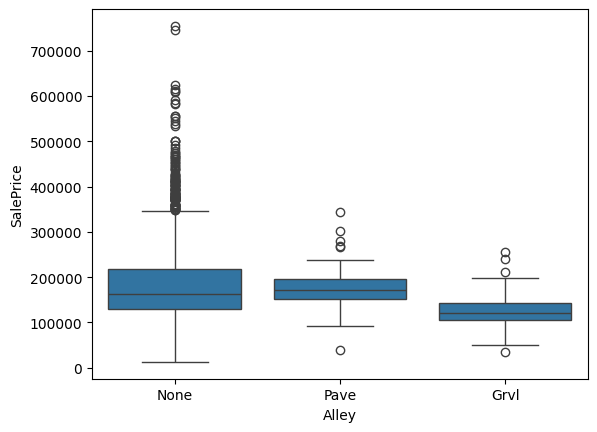

In [70]:
import seaborn as sns
sns.boxplot(x=df["Alley"].fillna("None"), y=df["SalePrice"])

In [71]:
df["Alley"].value_counts(dropna=False)

,count
Alley,
NaN,2732
Grvl,120
Pave,78


In [72]:
df["Fence"].value_counts(dropna=False)

,count
Fence,
NaN,2358
MnPrv,330
GdPrv,118
GdWo,112
MnWw,12


In [73]:
df["Alley"] = df["Alley"].fillna("None")
df["Fence"] = df["Fence"].fillna("None")

I filled NA values in Alley and Fence with "None", since NA means "no alley access" /
"no fence" here. This way, one-hot encoding keeps "none" as its own category.

In [74]:
df.drop(["Pool QC","Pool Area", "Misc Feature", "Misc Val"], axis=1, inplace=True)

In [75]:
df.drop(["Order","PID"], axis=1, inplace=True)

In [76]:
df.corr(numeric_only=True)["SalePrice"].sort_values(ascending=False)

,SalePrice
SalePrice,1.000000
Overall Qual,0.799262
Gr Liv Area,0.706780
Garage Cars,0.647877
Garage Area,0.640401
Total Bsmt SF,0.632280
1st Flr SF,0.621676
Year Built,0.558426
Full Bath,0.545604
Year Remod/Add,0.532974


In [77]:
df.groupby("MS SubClass")["SalePrice"].agg(["count","median"])

,count,median
MS SubClass,,
20,1079,158900.0
30,139,99500.0
40,6,134750.0
45,18,113000.0
50,287,130000.0
60,575,215000.0
70,128,146750.0
75,23,164000.0
80,118,165000.0


kategorik (ordinal) olanları numerik yapıyoruz.

In [78]:
qual_map = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1}
fin_map  = {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1}

ordinal_maps = {

    "Exter Qual":     qual_map,
    "Exter Cond":     qual_map,
    "Bsmt Qual":      qual_map,
    "Bsmt Cond":      qual_map,
    "Heating QC":     qual_map,
    "Kitchen Qual":   qual_map,
    "Fireplace Qu":   qual_map,
    "Garage Qual":    qual_map,
    "Garage Cond":    qual_map,

    "Lot Shape":      {"Reg": 4, "IR1": 3, "IR2": 2, "IR3": 1},
    "Utilities":      {"AllPub": 4, "NoSewr": 3, "NoSeWa": 2, "ELO": 1},
    "Land Slope":     {"Gtl": 3, "Mod": 2, "Sev": 1},
    "Bsmt Exposure":  {"Gd": 4, "Av": 3, "Mn": 2, "No": 1},
    "BsmtFin Type 1": fin_map,
    "BsmtFin Type 2": fin_map,
    "Functional":     {"Typ": 8, "Min1": 7, "Min2": 6, "Mod": 5,
                       "Maj1": 4, "Maj2": 3, "Sev": 2, "Sal": 1},
    "Garage Finish":  {"Fin": 3, "RFn": 2, "Unf": 1},
    "Paved Drive":    {"Y": 3, "P": 2, "N": 1},
}

for col, mapping in ordinal_maps.items():
    df[col] = df[col].map(mapping).fillna(0)

df[list(ordinal_maps)].isnull().sum().sum()

np.int64(0)

These columns are ordinal: their categories have a natural order (e.g. Ex > Gd > TA).
So I mapped them to ordered numbers. One-hot encoding would have lost this ordering.
I mapped NA to 0, because NA here means the feature doesn't exist (e.g. no basement),
which logically sits below the lowest quality level.

In [79]:
df.select_dtypes("object").columns

Index(['MS Zoning', 'Street', 'Alley', 'Land Contour', 'Lot Config',
       'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Foundation', 'Heating', 'Central Air',
       'Electrical', 'Garage Type', 'Fence', 'Sale Type', 'Sale Condition'],
      dtype='object')

In [80]:
pd.get_dummies(df.copy()).shape

(2930, 229)

In [81]:
df.groupby(df["Electrical"])["SalePrice"].agg(["count", "median"])

,count,median
Electrical,,
FuseA,188,123750.0
FuseF,50,106000.0
FuseP,8,78500.0
Mix,1,67000.0
SBrkr,2682,167870.0


In [82]:
df["MS SubClass"] = df["MS SubClass"].astype(str)

df_encoded = pd.get_dummies(df, dtype=int)
df_encoded.shape

(2930, 244)

In [83]:
# sutunlar arası korelasyon incelenecek.

corr = df_encoded.corr()["SalePrice"].sort_values(ascending=False)

In [84]:
corr.head(20)

,SalePrice
SalePrice,1.000000
Overall Qual,0.799262
Gr Liv Area,0.706780
Exter Qual,0.697970
Kitchen Qual,0.672914
Garage Cars,0.647877
Garage Area,0.640401
Total Bsmt SF,0.632280
1st Flr SF,0.621676
Bsmt Qual,0.607532


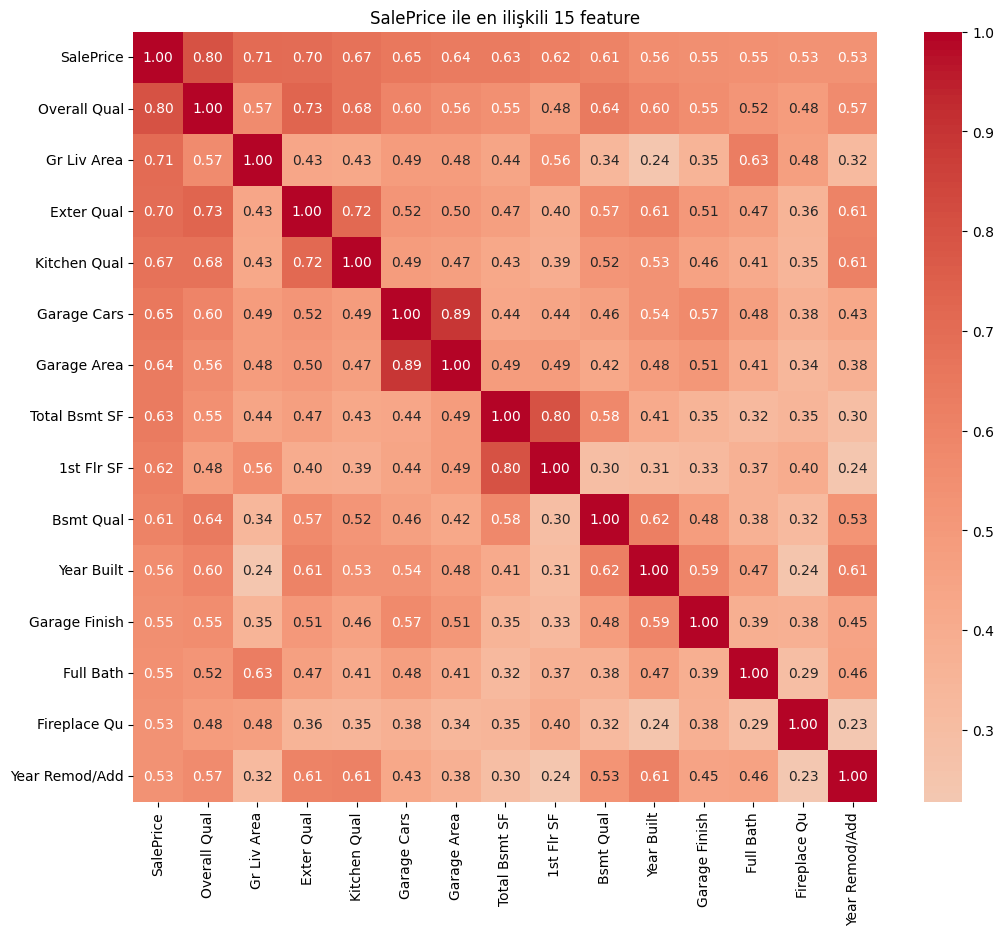

In [85]:

top_cols = corr.abs().sort_values(ascending=False).head(15).index

plt.figure(figsize=(12, 10))
sns.heatmap(df_encoded[top_cols].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("SalePrice ile en ilişkili 15 feature")
plt.show()

In [86]:
df[["Year Built", "Garage Yr Blt"]].corr()

,Year Built,Garage Yr Blt
Year Built,1.000000,0.834849
Garage Yr Blt,0.834849,1.000000


* Year Built and Garage Yr Blt are highly correlated (0.83), so I keep only one: Year Built.

- Year Built has a higher correlation with SalePrice, has no missing values,
  and is easier to explain.

Garage Cars and Garage Area carry nearly the same information, so keeping both
isn't useful. I keep Garage Cars.

In [87]:
df[["Total Bsmt SF", "1st Flr SF"]].corr()

,Total Bsmt SF,1st Flr SF
Total Bsmt SF,1.00000,0.80072
1st Flr SF,0.80072,1.00000


In [88]:
drop_cols = ["Garage Area", "Garage Yr Blt"]

df = df.drop(columns=drop_cols)
df_encoded = df_encoded.drop(columns=drop_cols)

print(df.shape, df_encoded.shape)

(2930, 74) (2930, 242)


In [89]:
corr.tail(10)

,SalePrice
Sale Type_WD,-0.204369
Neighborhood_OldTown,-0.211944
Foundation_BrkTil,-0.227316
MS SubClass_30,-0.234890
Roof Style_Gable,-0.256250
Central Air_N,-0.264506
Lot Shape,-0.291420
MS Zoning_RM,-0.292590
Foundation_CBlock,-0.349642
Garage Type_Detchd,-0.365074


In [90]:
df.groupby("Foundation")[["Year Built", "SalePrice"]].median()

,Year Built,SalePrice
Foundation,,
BrkTil,1923.0,123000.0
CBlock,1963.0,140000.0
PConc,2002.0,208400.0
Slab,1955.0,103000.0
Stone,1900.0,118000.0
Wood,1993.0,164000.0


In [91]:
df.groupby("Garage Type")[["Year Built", "SalePrice"]].median()

,Year Built,SalePrice
Garage Type,,
2Types,1960.0,150000.0
Attchd,1990.0,185000.0
Basment,1958.0,145250.0
BuiltIn,2003.0,229400.0
CarPort,1962.0,101800.0
Detchd,1945.0,129900.0


The negative correlations of Foundation and Garage Type appear to be related to house age:
these features are more common in older houses, and older houses tend to be cheaper.

The dataset's "Special Notes" recommend removing houses larger than 4,000 sq ft.
Three of these five houses were partial sales, sold far below what their size suggests,
which could mislead the model. I removed all five.

In [92]:
df[df["Gr Liv Area"] > 4000][["Gr Liv Area", "SalePrice", "Sale Condition"]]

,Gr Liv Area,SalePrice,Sale Condition
1498,5642,160000,Partial
1760,4476,745000,Abnorml
1767,4316,755000,Normal
2180,5095,183850,Partial
2181,4676,184750,Partial


In [93]:
outliers = df["Gr Liv Area"] > 4000
print(outliers.sum())   # 5 olmalı

df = df[~outliers]
df_encoded = df_encoded[~outliers]

print(df.shape, df_encoded.shape)   # (2925, 74) (2925, 242)

5
(2925, 74) (2925, 242)


# Train and test

In [94]:
Y = df_encoded[["SalePrice"]]
X = df_encoded.drop("SalePrice",axis=1)

In [95]:
X_train,X_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=2)

In [96]:
X_train

,Lot Frontage,Lot Area,Lot Shape,Utilities,Land Slope,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
1167,NaN,4765,3,4,3,9,5,2000,2000,260.0,...,0,0,0,1,0,0,0,0,1,0
2751,64.0,7488,3,4,3,7,5,2005,2005,0.0,...,0,0,0,1,1,0,0,0,0,0
369,85.0,11900,4,4,3,5,6,1977,1977,157.0,...,0,0,0,1,0,0,0,0,1,0
194,50.0,6000,4,4,3,6,7,1939,1950,0.0,...,0,0,0,1,1,0,0,0,0,0
2421,NaN,3196,4,4,3,8,5,2003,2003,40.0,...,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2519,36.0,3640,3,4,3,8,5,1980,1980,0.0,...,0,0,0,1,0,0,0,0,1,0
2352,NaN,9927,3,4,3,7,5,1976,1976,252.0,...,0,0,0,1,0,0,0,0,1,0
1609,NaN,11075,3,4,2,5,4,1969,1969,232.0,...,0,0,0,1,0,0,0,0,1,0
2546,NaN,10368,3,4,3,6,6,1964,1964,112.0,...,0,0,0,1,0,0,0,0,1,0


In [97]:
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
print(f"Baseline RMSE: {baseline_rmse:,.0f} $")

Baseline RMSE: 73,385 $


Without knowing anything about a house, predicting the average price gives
an error of around $80k. This is the baseline every model must beat.

In [98]:
df.SalePrice.mean()

np.float64(180411.5747008547)

In [99]:
X_train.isnull().sum()[X_train.isnull().sum() > 0]

,0
Lot Frontage,390
Mas Vnr Area,19
BsmtFin SF 1,1
BsmtFin SF 2,1
Bsmt Unf SF,1
Total Bsmt SF,1
Bsmt Full Bath,2
Bsmt Half Bath,2
Garage Cars,1


In [100]:
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

Linear regression


In [101]:
model=LinearRegression()
model.fit(X_train,y_train)

y_pred=model.predict(X_test)

In [102]:
mse=mean_squared_error(y_test,y_pred)
mse

430550077.3568367

In [103]:
model.score(X_train,y_train)

0.9301727155173808

MSE is in squared dollars, so the number is huge and hard to interpret directly.
Taking the square root gives RMSE, which is in dollars.

In [104]:
rmse = np.sqrt(mse)
rmse

np.float64(20749.7006570417)

In [105]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.9199972510072245

In [106]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV

models = {
    "Linear": LinearRegression(),
    "Ridge":  RidgeCV(alphas=[0.1, 1, 10, 100, 1000]),
    "Lasso":  LassoCV(cv=5, max_iter=10000, random_state=2),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
}

results = []
for name, model in models.items():
    pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model),
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
    })

pd.DataFrame(results)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:1664: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,Model,RMSE,R2
0,Linear,20844.278705,0.919266
1,Ridge,20455.124559,0.922253
2,Lasso,20551.044644,0.921522
3,Random Forest,23176.997240,0.900185


Regularization (Ridge and Lasso) made very little difference, so there is no sign
of serious overfitting.

* All four models landed around $25k RMSE. Switching models didn't help, so the next step
  is on the data side: a log transform (because of expensive houses) and outliers.

After removing outliers, the linear models improved by ~20%, while Random Forest
was barely affected.

In [ ]:
from sklearn.model_selection import cross_val_score, KFold, GridSearchCV

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Ridge:
ridge_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", RidgeCV(alphas=[0.1, 1, 10, 100, 1000])),
])
ridge_scores = -cross_val_score(ridge_pipe, X_train, y_train, cv=kf,
                                scoring="neg_root_mean_squared_error")

# Random Forest:
rf_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1)),
])
param_grid = {
    "model__n_estimators": [200, 500],
    "model__max_features": [0.3, 0.5, 1.0],
    "model__min_samples_leaf": [1, 3],
}
grid = GridSearchCV(rf_pipe, param_grid, cv=kf,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_train, y_train)


print("Ridge CV RMSE:", round(ridge_scores.mean()), "±", round(ridge_scores.std()))
print("RF en iyi parametreler:", grid.best_params_)
print("RF en iyi CV RMSE:", round(-grid.best_score_))

In [ ]:
from xgboost import XGBRegressor

xgb_pipe = Pipeline([
    ("model", XGBRegressor(
        n_estimators=1000,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.5,
        random_state=42,
        n_jobs=-1,
    )),
])

xgb_scores = -cross_val_score(xgb_pipe, X_train, y_train, cv=kf,
                              scoring="neg_root_mean_squared_error")
print("XGBoost CV RMSE:", round(xgb_scores.mean()), "±", round(xgb_scores.std()))

In [ ]:
from sklearn.compose import TransformedTargetRegressor

def with_log(pipe):
    return TransformedTargetRegressor(
        regressor=pipe, func=np.log1p, inverse_func=np.expm1
    )

log_models = {
    "Ridge (log)": with_log(Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", RidgeCV(alphas=[0.1, 1, 10, 100, 1000])),
    ])),
    "Random Forest (log)": with_log(Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(n_estimators=500, max_features=0.3,
                                        random_state=42, n_jobs=-1)),
    ])),
    "XGBoost (log)": with_log(Pipeline([
        ("model", XGBRegressor(n_estimators=1000, learning_rate=0.05,
                               max_depth=4, subsample=0.8,
                               colsample_bytree=0.5,
                               random_state=42, n_jobs=-1)),
    ])),
}

for name, model in log_models.items():
    scores = -cross_val_score(model, X_train, y_train, cv=kf,
                              scoring="neg_root_mean_squared_error")
    print(f"{name}: {scores.mean():,.0f} ± {scores.std():,.0f}")

* XGBoost (with log-transformed target) is the best model. Next, I tune its
  hyperparameters with grid search.

In [ ]:
xgb_log = with_log(Pipeline([
    ("model", XGBRegressor(n_estimators=1000, subsample=0.8,
                           random_state=42, n_jobs=-1)),
]))

param_grid = {
    "regressor__model__max_depth": [3, 4, 5],
    "regressor__model__learning_rate": [0.03, 0.05, 0.1],
    "regressor__model__colsample_bytree": [0.3, 0.5],
}

grid_xgb = GridSearchCV(xgb_log, param_grid, cv=kf,
                        scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_xgb.fit(X_train, y_train)

print("En iyi parametreler:", grid_xgb.best_params_)
print("En iyi CV RMSE:", round(-grid_xgb.best_score_))

In [ ]:
final_model = grid_xgb.best_estimator_
test_pred = final_model.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_r2 = r2_score(y_test, test_pred)

print(f"Test RMSE: {test_rmse:,.0f} $")
print(f"Test R²: {test_r2:.3f}")

On unseen houses, the model predicts the price with a typical error of about $19k,
roughly 10% of the average house price. It explains 93% of the variation in prices
between houses (R² = 0.93).